In [1]:
import os
import sys
import glob
import time
import hashlib
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
import torch
import torchvision.transforms as transforms
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import json

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore')
plt.style.use('default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10
sns.set_theme(style='whitegrid', palette='muted')

def resolve_dataset_path(candidate_paths, description):
    for candidate in candidate_paths:
        if os.path.exists(candidate):
            return os.path.abspath(candidate)
    searched_list = "\n  * ".join(candidate_paths)
    err_message = f"\nUnable to locate: {description}\nSearched:\n  * {searched_list}\n"
    raise FileNotFoundError(err_message)

SOIL_IMAGE_CANDIDATES = [
    "Soil Image Dataset",
    "../Soil Image Dataset",
    "./AIML/Soil Image Dataset",
    "AIML/Soil Image Dataset"
]
SOIL_IMAGE_DATA_PATH = resolve_dataset_path(SOIL_IMAGE_CANDIDATES, "Soil Image Dataset Directory")

BASE_DIR = os.path.dirname(SOIL_IMAGE_DATA_PATH)
if os.path.basename(BASE_DIR) == "Soil Image Dataset":
    BASE_DIR = os.path.dirname(BASE_DIR)

DL_OUTPUT_DIR = os.path.join(BASE_DIR, "preprocessed_output", "DL")
SOIL_DIR = os.path.join(DL_OUTPUT_DIR, "soil_images")
REPORT_DIR = os.path.join(DL_OUTPUT_DIR, "reports")
PREPROCESSED_IMG_DIR = os.path.join(SOIL_DIR, "preprocessed_images")

for d in [SOIL_DIR, REPORT_DIR, PREPROCESSED_IMG_DIR]:
    os.makedirs(d, exist_ok=True)

print("Deep Learning Environment & Directories Initialized Successfully")
print("Base Path:", BASE_DIR)
print("Soil Image Dataset Root:", SOIL_IMAGE_DATA_PATH)
print("DL Output Directory:", DL_OUTPUT_DIR)
print("Preprocessed Images Directory:", PREPROCESSED_IMG_DIR)


Deep Learning Environment & Directories Initialized Successfully
Base Path: C:\Users\khanp\Downloads\infosy virtual intership 7.0\AIML
Soil Image Dataset Root: C:\Users\khanp\Downloads\infosy virtual intership 7.0\AIML\Soil Image Dataset
DL Output Directory: C:\Users\khanp\Downloads\infosy virtual intership 7.0\AIML\preprocessed_output\DL
Preprocessed Images Directory: C:\Users\khanp\Downloads\infosy virtual intership 7.0\AIML\preprocessed_output\DL\soil_images\preprocessed_images


In [2]:
def compute_file_md5(filepath, chunk_size=65536):
    hasher = hashlib.md5()
    with open(filepath, 'rb') as f:
        buf = f.read(chunk_size)
        while len(buf) > 0:
            hasher.update(buf)
            buf = f.read(chunk_size)
    return hasher.hexdigest()

SUPPORTED_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
subdirectories = [d for d in os.listdir(SOIL_IMAGE_DATA_PATH) if os.path.isdir(os.path.join(SOIL_IMAGE_DATA_PATH, d))]
discovered_classes = sorted(subdirectories) if subdirectories else ['Unclassified']

all_image_records = []
for root, dirs, files in os.walk(SOIL_IMAGE_DATA_PATH):
    for f in files:
        full_path = os.path.join(root, f)
        ext = os.path.splitext(f)[1].lower()
        rel_dir = os.path.relpath(root, SOIL_IMAGE_DATA_PATH)
        assigned_label = 'Unclassified' if rel_dir == '.' else rel_dir.split(os.sep)[0]
        is_supported = ext in SUPPORTED_EXTENSIONS
        all_image_records.append({
            'file_path': full_path,
            'filename': f,
            'extension': ext,
            'class_label': assigned_label,
            'is_supported': is_supported,
            'file_size_bytes': os.path.getsize(full_path)
        })

inventory_df = pd.DataFrame(all_image_records)
display(inventory_df['extension'].value_counts().to_frame(name='File Count'))

verified_records = []
corrupted_files = []
unsupported_files = []

for idx, row in inventory_df.iterrows():
    fpath = row['file_path']
    if not row['is_supported']:
        unsupported_files.append(fpath)
        verified_records.append({
            **row,
            'is_valid': False,
            'width': None,
            'height': None,
            'channels': None,
            'aspect_ratio': None,
            'color_mode': 'Unsupported',
            'md5_hash': None,
            'preprocessed_dest': None
        })
        continue

    try:
        f_hash = compute_file_md5(fpath)
        with Image.open(fpath) as img:
            img.verify()
        with Image.open(fpath) as img:
            w, h = img.size
            mode = img.mode
            channels = len(img.getbands())
            ratio = round(w / h, 4) if h > 0 else 0
            verified_records.append({
                **row,
                'is_valid': True,
                'width': w,
                'height': h,
                'channels': channels,
                'aspect_ratio': ratio,
                'color_mode': mode,
                'md5_hash': f_hash,
                'preprocessed_dest': None
            })
    except Exception as exc:
        corrupted_files.append((fpath, str(exc)))
        verified_records.append({
            **row,
            'is_valid': False,
            'width': None,
            'height': None,
            'channels': None,
            'aspect_ratio': None,
            'color_mode': 'Corrupt',
            'md5_hash': None,
            'preprocessed_dest': None
        })

verified_df = pd.DataFrame(verified_records)

hash_counts = verified_df[verified_df['is_valid']]['md5_hash'].value_counts()
duplicate_hashes = hash_counts[hash_counts > 1]
total_duplicates = duplicate_hashes.sum() - len(duplicate_hashes)
verified_df['is_duplicate'] = verified_df['md5_hash'].map(lambda h: (h in duplicate_hashes) if pd.notnull(h) else False)

class_dist_df = verified_df[verified_df['is_valid']].groupby('class_label').agg(
    Valid_Images=('filename', 'count'),
    Duplicates=('is_duplicate', 'sum'),
    Avg_Width=('width', 'mean'),
    Avg_Height=('height', 'mean'),
    Min_Width=('width', 'min'),
    Max_Width=('width', 'max')
).reset_index()
display(class_dist_df)


           File Count
extension            
.jpeg            4003
.jpg             2299
.webp               7
.png                6
.gif                2
     class_label  Valid_Images  Duplicates  ...  Avg_Height  Min_Width  Max_Width
0  Alluvial soil          1221         495  ...  360.820639      100.0     1500.0
1      Arid_Soil           284           9  ...  521.778169      156.0     3888.0
2     Black Soil          1404         222  ...  294.636040      100.0     3484.0
3      Clay soil           199         152  ...  490.919598      100.0     2592.0
4  Laterite_Soil           219          10  ...  521.045662      161.0     2940.0
5  Mountain_Soil           201          20  ...  571.303483      166.0     3000.0
6       Red soil          1386         212  ...  282.253247      100.0     2560.0
7    Yellow_Soil          1401          12  ...  265.894361      174.0     1600.0

[8 rows x 7 columns]


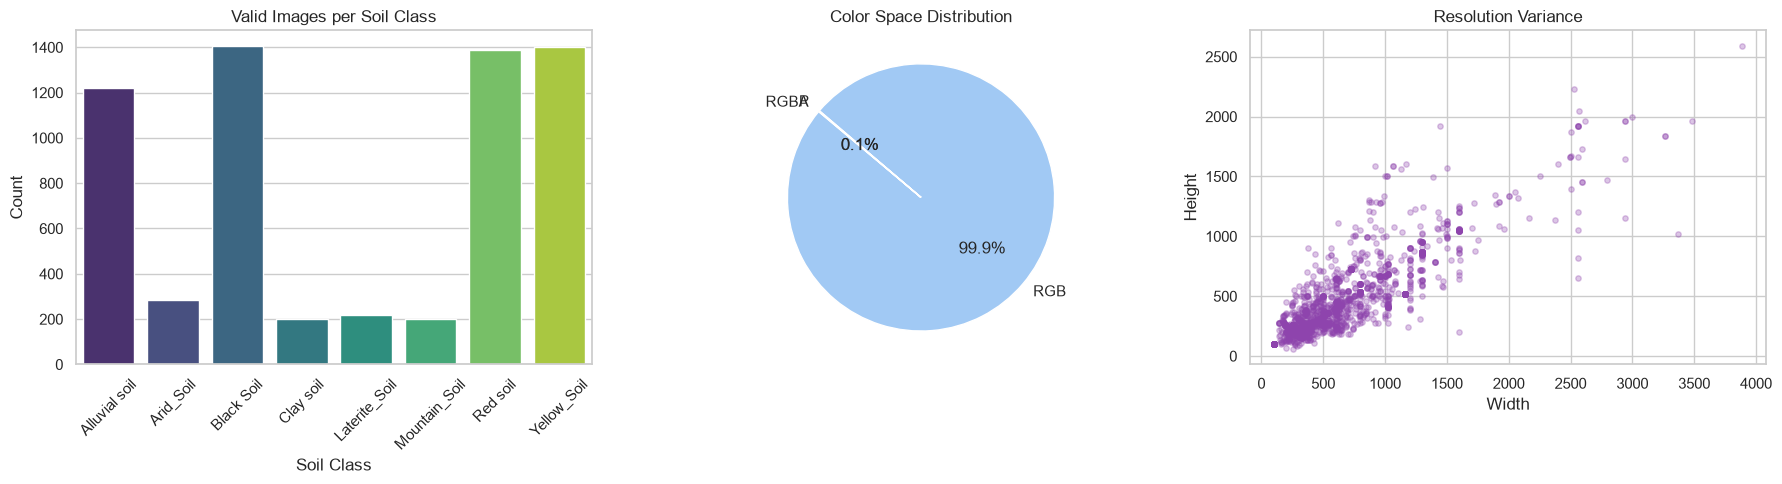

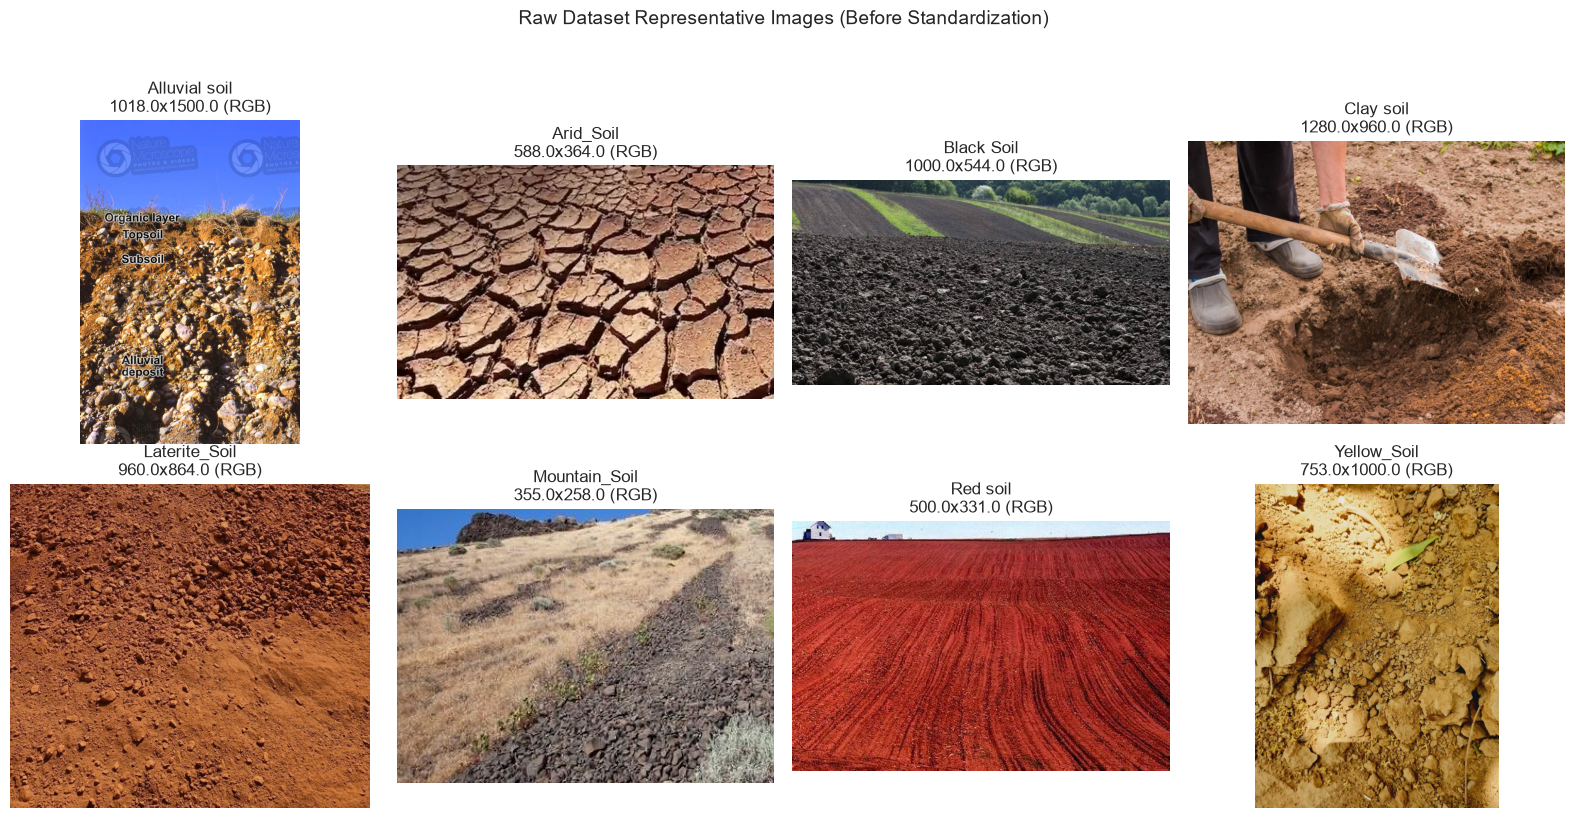

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=class_dist_df, x='class_label', y='Valid_Images', ax=axes[0], palette='viridis')
axes[0].set_title("Valid Images per Soil Class")
axes[0].set_xlabel("Soil Class")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', rotation=45)

mode_counts = verified_df[verified_df['is_valid']]['color_mode'].value_counts()
axes[1].pie(mode_counts, labels=mode_counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'), startangle=140)
axes[1].set_title("Color Space Distribution")

valid_imgs = verified_df[verified_df['is_valid']]
axes[2].scatter(valid_imgs['width'], valid_imgs['height'], alpha=0.3, color='#8e44ad', s=15)
axes[2].set_title("Resolution Variance")
axes[2].set_xlabel("Width")
axes[2].set_ylabel("Height")
plt.tight_layout()
plt.show()

sample_images = []
for cl in class_dist_df['class_label']:
    cl_subset = verified_df[(verified_df['class_label'] == cl) & (verified_df['is_valid'])]
    if not cl_subset.empty:
        sample_images.append(cl_subset.iloc[0])

num_samples = len(sample_images)
cols = 4
rows = (num_samples + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = axes.flatten()

for i, record in enumerate(sample_images):
    img = Image.open(record['file_path'])
    axes[i].imshow(img)
    axes[i].set_title(f"{record['class_label']}\n{record['width']}x{record['height']} ({record['color_mode']})")
    axes[i].axis('off')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle("Raw Dataset Representative Images (Before Standardization)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


In [4]:
def standardize_and_process_image(file_path, target_size=(224, 224)):
    with Image.open(file_path) as img:
        if img.mode in ('RGBA', 'LA'):
            bg = Image.new('RGB', img.size, (255, 255, 255))
            bg.paste(img, mask=img.split()[-1])
            rgb_img = bg
        elif img.mode != 'RGB':
            rgb_img = img.convert('RGB')
        else:
            rgb_img = img.copy()
        resized_img = rgb_img.resize(target_size, Image.Resampling.LANCZOS)
        norm_array = np.asarray(resized_img, dtype=np.float32) / 255.0
        return resized_img, norm_array

preprocessed_metadata = []
for idx, row in verified_df.iterrows():
    item = dict(row)
    if row['is_valid']:
        class_folder = os.path.join(PREPROCESSED_IMG_DIR, row['class_label'])
        os.makedirs(class_folder, exist_ok=True)
        dest_filename = f"{os.path.splitext(row['filename'])[0]}.jpg"
        dest_path = os.path.join(class_folder, dest_filename)

        if not os.path.exists(dest_path):
            resized_img, _ = standardize_and_process_image(row['file_path'])
            resized_img.save(dest_path, 'JPEG', quality=95)

        item['preprocessed_dest'] = dest_path
        item['preprocessed_width'] = 224
        item['preprocessed_height'] = 224
        item['preprocessed_channels'] = 3
    preprocessed_metadata.append(item)

soil_manifest_df = pd.DataFrame(preprocessed_metadata)
manifest_export_path = os.path.join(SOIL_DIR, "soil_image_manifest.csv")
soil_manifest_df.to_csv(manifest_export_path, index=False)
print("Standardized Image Preprocessing Complete (224x224 RGB)")
print("Image Manifest Exported to:", manifest_export_path)


Standardized Image Preprocessing Complete (224x224 RGB)
Image Manifest Exported to: C:\Users\khanp\Downloads\infosy virtual intership 7.0\AIML\preprocessed_output\DL\soil_images\soil_image_manifest.csv


In [5]:
valid_manifest = soil_manifest_df[soil_manifest_df['is_valid']].copy()
image_encoder = LabelEncoder()
valid_manifest['class_idx'] = image_encoder.fit_transform(valid_manifest['class_label'])
unique_hashes = valid_manifest.drop_duplicates(subset=['md5_hash'])[['md5_hash', 'class_idx']]
train_hashes, temp_hashes = train_test_split(
    unique_hashes, test_size=0.30, random_state=42, stratify=unique_hashes['class_idx']
)
val_hashes, test_hashes = train_test_split(
    temp_hashes, test_size=0.50, random_state=42, stratify=temp_hashes['class_idx']
)
train_manifest = valid_manifest[valid_manifest['md5_hash'].isin(train_hashes['md5_hash'])]
val_manifest = valid_manifest[valid_manifest['md5_hash'].isin(val_hashes['md5_hash'])]
test_manifest = valid_manifest[valid_manifest['md5_hash'].isin(test_hashes['md5_hash'])]
train_manifest.to_csv(os.path.join(SOIL_DIR, 'soil_image_train_split.csv'), index=False)
val_manifest.to_csv(os.path.join(SOIL_DIR, 'soil_image_val_split.csv'), index=False)
test_manifest.to_csv(os.path.join(SOIL_DIR, 'soil_image_test_split.csv'), index=False)
image_mapping = {int(k): v for k, v in enumerate(image_encoder.classes_)}
with open(os.path.join(SOIL_DIR, 'soil_class_mapping.json'), 'w') as f:
    json.dump(image_mapping, f, indent=2)

dl_partition_summary = pd.DataFrame({
    'Partition': ['Train (70%)', 'Validation (15%)', 'Test (15%)'],
    'Image Count': [f'{len(train_manifest):,} images', f'{len(val_manifest):,} images', f'{len(test_manifest):,} images'],
    'Unique MD5 Hashes': [len(train_hashes), len(val_hashes), len(test_hashes)],
    'Target Dimensions': ['224x224 RGB', '224x224 RGB', '224x224 RGB'],
    'Status': ['MODEL-READY', 'MODEL-READY', 'MODEL-READY']
})
display(dl_partition_summary)


          Partition   Image Count  ...  Target Dimensions       Status
0       Train (70%)  4,407 images  ...        224x224 RGB  MODEL-READY
1  Validation (15%)    948 images  ...        224x224 RGB  MODEL-READY
2        Test (15%)    960 images  ...        224x224 RGB  MODEL-READY

[3 rows x 5 columns]


In [6]:
train_sample_paths = train_manifest['preprocessed_dest'].dropna().tolist()[:600]
channel_sum = np.zeros(3)
channel_sum_sq = np.zeros(3)
pixel_count = 0

for p in train_sample_paths:
    if os.path.exists(p):
        arr = np.asarray(Image.open(p), dtype=np.float32) / 255.0
        channel_sum += arr.sum(axis=(0, 1))
        channel_sum_sq += (arr ** 2).sum(axis=(0, 1))
        pixel_count += arr.shape[0] * arr.shape[1]

channel_mean = (channel_sum / pixel_count).tolist()
channel_std = np.sqrt(channel_sum_sq / pixel_count - (channel_sum / pixel_count) ** 2).tolist()

norm_stats = {
    'channel_mean_rgb': [round(x, 4) for x in channel_mean],
    'channel_std_rgb': [round(x, 4) for x in channel_std],
    'target_size': [224, 224],
    'color_space': 'RGB'
}
with open(os.path.join(SOIL_DIR, 'soil_normalization_stats.json'), 'w') as f:
    json.dump(norm_stats, f, indent=2)

norm_df = pd.DataFrame({
    'Channel': ['Red', 'Green', 'Blue'],
    'Dataset Mean': [round(x, 4) for x in channel_mean],
    'Dataset Std': [round(x, 4) for x in channel_std],
    'Standard ImageNet Mean': [0.485, 0.456, 0.406],
    'Standard ImageNet Std': [0.229, 0.224, 0.225]
})
display(norm_df)


  Channel  Dataset Mean  ...  Standard ImageNet Mean  Standard ImageNet Std
0     Red        0.6830  ...                   0.485                  0.229
1   Green        0.5182  ...                   0.456                  0.224
2    Blue        0.3488  ...                   0.406                  0.225

[3 rows x 5 columns]


In [7]:
class_indices = valid_manifest['class_idx'].values
soil_classes = np.unique(class_indices)
weights = compute_class_weight(class_weight='balanced', classes=soil_classes, y=class_indices)
soil_weight_dict = {image_encoder.classes_[i]: round(float(weights[i]), 4) for i in range(len(weights))}

with open(os.path.join(SOIL_DIR, 'soil_class_weights.json'), 'w') as f:
    json.dump(soil_weight_dict, f, indent=2)

weights_df = pd.DataFrame({
    'Class Index': list(soil_classes),
    'Soil Class': [image_encoder.classes_[i] for i in soil_classes],
    'Sample Count': [int((class_indices == i).sum()) for i in soil_classes],
    'Balanced Loss Weight': [round(float(weights[i]), 4) for i in range(len(weights))]
}).sort_values(by='Balanced Loss Weight', ascending=False)
display(weights_df)


   Class Index     Soil Class  Sample Count  Balanced Loss Weight
3            3      Clay soil           199                3.9667
5            5  Mountain_Soil           201                3.9272
4            4  Laterite_Soil           219                3.6045
1            1      Arid_Soil           284                2.7795
0            0  Alluvial soil          1221                0.6465
6            6       Red soil          1386                0.5695
7            7    Yellow_Soil          1401                0.5634
2            2     Black Soil          1404                0.5622


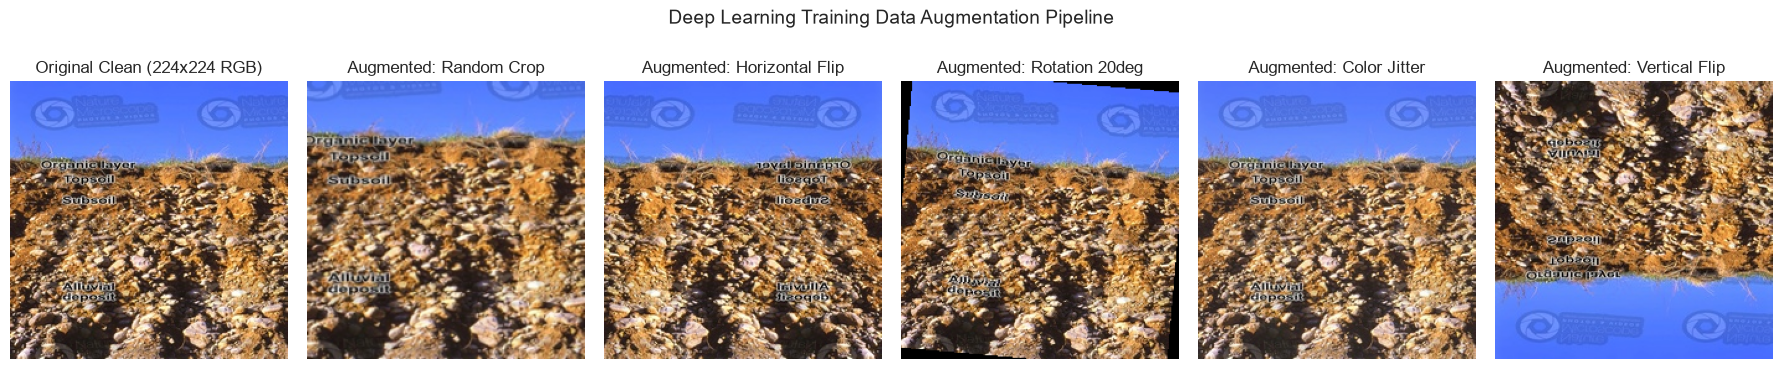

In [8]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=channel_mean, std=channel_std)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=channel_mean, std=channel_std)
])

demo_img_path = train_manifest.iloc[0]['preprocessed_dest']
demo_img = Image.open(demo_img_path)

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
axes[0].imshow(demo_img)
axes[0].set_title("Original Clean (224x224 RGB)")
axes[0].axis('off')

demo_aug_transforms = [
    ("Random Crop", transforms.RandomResizedCrop(224, scale=(0.7, 0.9))),
    ("Horizontal Flip", transforms.RandomHorizontalFlip(p=1.0)),
    ("Rotation 20deg", transforms.RandomRotation(degrees=20)),
    ("Color Jitter", transforms.ColorJitter(brightness=0.2, contrast=0.2)),
    ("Vertical Flip", transforms.RandomVerticalFlip(p=1.0))
]

for idx, (name, t) in enumerate(demo_aug_transforms):
    aug_img = t(demo_img)
    axes[idx + 1].imshow(aug_img)
    axes[idx + 1].set_title(f"Augmented: {name}")
    axes[idx + 1].axis('off')

plt.suptitle("Deep Learning Training Data Augmentation Pipeline", y=1.05, fontsize=14)
plt.tight_layout()
plt.show()


                     Dataset  ...                      Quality Status
0  Soil Image Classification  ...  VERIFIED / READY FOR DEEP LEARNING

[1 rows x 12 columns]
Preprocessed Images on Disk: 6315
All Deep Learning Preprocessing & Split Integrity Assertions Passed (100% Leak-Free)

Soil Images Directory (7 files):
  * soil_class_mapping.json             :     0.18 KB
  * soil_class_weights.json             :     0.20 KB
  * soil_image_manifest.csv             :  2293.61 KB
  * soil_image_test_split.csv           :   350.75 KB
  * soil_image_train_split.csv          :  1608.31 KB
  * soil_image_val_split.csv            :   347.00 KB
  * soil_normalization_stats.json       :     0.20 KB

DL Reports Directory (2 files):
  * dl_preprocessing_summary.csv        :     0.41 KB
  * soil_image_preprocessing_report.csv :     0.33 KB

DEEP LEARNING DATA PREPROCESSING COMPLETE & VERIFIED


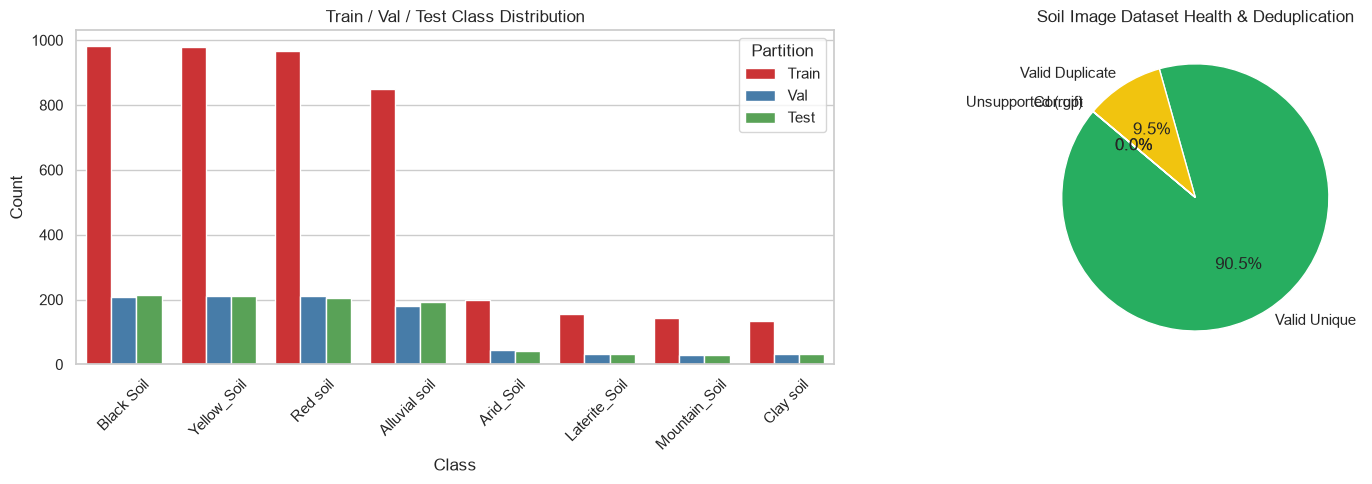

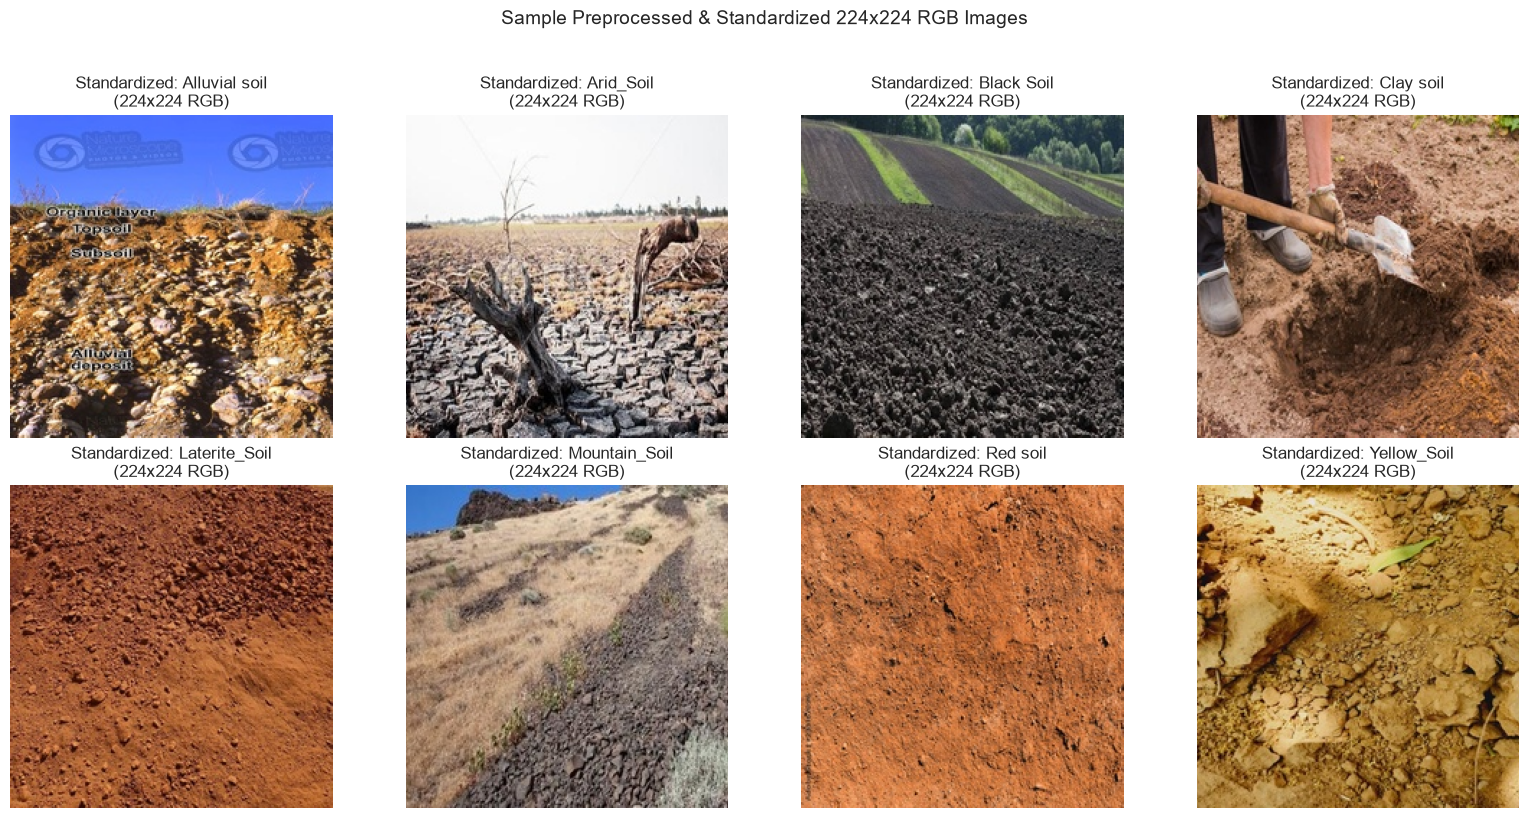

In [9]:
dl_summary_record = [{
    'Dataset': 'Soil Image Classification',
    'Data Modality': 'Computer Vision (RGB Images)',
    'Total Raw Discovered': f"{len(inventory_df):,} files",
    'Valid Processed Images': f"{len(valid_manifest):,} images",
    'Unsupported (.gif)': int((~verified_df['is_supported']).sum()),
    'Corrupt Images': int((verified_df['color_mode'] == 'Corrupt').sum()),
    'Duplicate Images Catalogued': int(total_duplicates),
    'Target Classes': len(image_encoder.classes_),
    'Standardized Resolution': '224x224 RGB',
    'Train / Val / Test Partition': f"{len(train_manifest)} / {len(val_manifest)} / {len(test_manifest)}",
    'Leakage Protection': 'MD5 Hash Grouped Stratification',
    'Quality Status': 'VERIFIED / READY FOR DEEP LEARNING'
}]

dl_summary_df = pd.DataFrame(dl_summary_record)
display(dl_summary_df)
dl_summary_path = os.path.join(REPORT_DIR, "dl_preprocessing_summary.csv")
dl_summary_df.to_csv(dl_summary_path, index=False)

soil_audit_report = pd.DataFrame({
    'Metric': [
        'Total Discovered Images',
        'Valid Processed Images',
        'Unsupported Files (.gif)',
        'Corrupt Files',
        'Duplicate Images Identified',
        'Total Classes',
        'Train Partition Count',
        'Validation Partition Count',
        'Test Partition Count',
        'Dataset RGB Mean',
        'Dataset RGB Std'
    ],
    'Value': [
        len(inventory_df),
        len(valid_manifest),
        int((~verified_df['is_supported']).sum()),
        int((verified_df['color_mode'] == 'Corrupt').sum()),
        int(total_duplicates),
        len(image_encoder.classes_),
        len(train_manifest),
        len(val_manifest),
        len(test_manifest),
        str([round(x, 3) for x in channel_mean]),
        str([round(x, 3) for x in channel_std])
    ]
})
soil_audit_report.to_csv(os.path.join(REPORT_DIR, "soil_image_preprocessing_report.csv"), index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
split_dist = pd.DataFrame({
    'Class': train_manifest['class_label'].value_counts().index,
    'Train': train_manifest['class_label'].value_counts().values,
    'Val': val_manifest['class_label'].value_counts().reindex(train_manifest['class_label'].value_counts().index).values,
    'Test': test_manifest['class_label'].value_counts().reindex(train_manifest['class_label'].value_counts().index).values
}).melt(id_vars='Class', var_name='Partition', value_name='Count')

sns.barplot(data=split_dist, x='Class', y='Count', hue='Partition', ax=axes[0], palette='Set1')
axes[0].set_title("Train / Val / Test Class Distribution")
axes[0].tick_params(axis='x', rotation=45)

image_health_data = pd.Series({
    'Valid Unique': len(valid_manifest) - total_duplicates,
    'Valid Duplicate': total_duplicates,
    'Unsupported (.gif)': (~verified_df['is_supported']).sum(),
    'Corrupt': (verified_df['color_mode'] == 'Corrupt').sum()
})
axes[1].pie(image_health_data, labels=image_health_data.index, autopct='%1.1f%%',
            colors=['#27ae60', '#f1c40f', '#e74c3c', '#7f8c8d'], startangle=140)
axes[1].set_title("Soil Image Dataset Health & Deduplication")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for idx, cname in enumerate(discovered_classes[:8]):
    samples = train_manifest[train_manifest['class_label'] == cname]
    if not samples.empty:
        sample_path = samples.iloc[0]['preprocessed_dest']
        img = Image.open(sample_path)
        axes[idx].imshow(img)
        axes[idx].set_title(f"Standardized: {cname}\n({img.size[0]}x{img.size[1]} RGB)")
        axes[idx].axis('off')
plt.suptitle("Sample Preprocessed & Standardized 224x224 RGB Images", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

reloaded_manifest = pd.read_csv(manifest_export_path)
reloaded_train = pd.read_csv(os.path.join(SOIL_DIR, 'soil_image_train_split.csv'))
reloaded_val = pd.read_csv(os.path.join(SOIL_DIR, 'soil_image_val_split.csv'))
reloaded_test = pd.read_csv(os.path.join(SOIL_DIR, 'soil_image_test_split.csv'))

assert len(reloaded_manifest) == len(soil_manifest_df)
assert len(reloaded_train) + len(reloaded_val) + len(reloaded_test) == len(valid_manifest)

train_hash_set = set(reloaded_train['md5_hash'])
val_hash_set = set(reloaded_val['md5_hash'])
test_hash_set = set(reloaded_test['md5_hash'])

assert len(train_hash_set.intersection(val_hash_set)) == 0
assert len(train_hash_set.intersection(test_hash_set)) == 0
assert len(val_hash_set.intersection(test_hash_set)) == 0

disk_preprocessed_count = len(glob.glob(os.path.join(PREPROCESSED_IMG_DIR, "*", "*.jpg")))
print("Preprocessed Images on Disk:", disk_preprocessed_count)
assert disk_preprocessed_count == len(valid_manifest)

print("All Deep Learning Preprocessing & Split Integrity Assertions Passed (100% Leak-Free)")

organized_dirs = {
    'Soil Images Directory': SOIL_DIR,
    'DL Reports Directory': REPORT_DIR
}

for desc, dpath in organized_dirs.items():
    files = [f for f in os.listdir(dpath) if os.path.isfile(os.path.join(dpath, f))]
    print(f"\n{desc} ({len(files)} files):")
    for f in sorted(files):
        sz_kb = os.path.getsize(os.path.join(dpath, f)) / 1024
        print(f"  * {f:<35} : {sz_kb:>8.2f} KB")

print("\nDEEP LEARNING DATA PREPROCESSING COMPLETE & VERIFIED")
